In [1]:
# Book scraping and Analysis
import requests
from bs4 import BeautifulSoup
import pandas as pd
import re

BASE_URL = "https://books.toscrape.com/catalogue/page-{}.html"
RATING_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

books = []

for page in range(1, 6):  # scrape only 5 pages = 100 books (change to 15 for 300 books)
    url = BASE_URL.format(page)
    resp = requests.get(url)
    soup = BeautifulSoup(resp.text, features="html.parser")

    for book in soup.find_all(name="article", class_="product_pod"):
        title = book.h3.a["title"]
     # PRICE
        price_raw = book.find(name="p", class_="price_color").text  # 'Â£51.77'
        price_clean = re.sub(r'[^0-9.]', '', price_raw)
        price = float(price_clean)

        rating_word = book.find(name="p", class_="star-rating")["class"][1]
        rating_num = RATING_MAP[rating_word]

        books.append({"title": title,
                      "price": price,  # Now clean number
                      "rating": rating_num})

    print(f"Page {page} done")

df = pd.DataFrame(books)
print(df.head())
print(f"Total books: {len(df)}")

df.to_csv("books_final_dataset.csv", index=False)
print("Saved to books_final_dataset.csv")

Page 1 done
Page 2 done
Page 3 done
Page 4 done
Page 5 done
                                   title  price  rating
0                   A Light in the Attic  51.77       3
1                     Tipping the Velvet  53.74       1
2                             Soumission  50.10       1
3                          Sharp Objects  47.82       4
4  Sapiens: A Brief History of Humankind  54.23       5
Total books: 100
Saved to books_final_dataset.csv


In [2]:
import pandas as pd
import numpy as np
import os

# Checking what files I actually have
print("Files in folder:", os.listdir("."))

# Trying to find the csv file - trying both names
if os.path.exists("books_final_dataset.csv"):
    df = pd.read_csv("books_final_dataset.csv")
    print("Loaded books_final_dataset.csv")
elif os.path.exists("books_raw_dataset.csv"):
    df = pd.read_csv("books_raw_dataset.csv")
    print("Loaded books_raw_dataset.csv")
else:
    print("ERROR: No csv file found! Run Book scraping first!")
    # Creating a small test dataframe so code doesn't crash
    df = pd.DataFrame({"title": ["Test"], "price": [10]})

print(df.head())

# Making sure price is numeric - handle £ symbol if still there
# If your price column has 'Â£51.77', clean it again
if df['price'].dtype == 'object':
    df['price'] = df['price'].astype(str).str.replace('£', '', regex=False).str.replace('Â', '', regex=False)

df["price"] = pd.to_numeric(df["price"], errors="coerce")

# Remove duplicates
df.drop_duplicates(subset="title", inplace=True)

print(df.describe())

# Save cleaned
df.to_csv("books_final_dataset_cleaned.csv", index=False)
print("Saved cleaned file!")

Files in folder: ['.idea', '.venv', 'books_final_dataset.csv', 'Books_To_Scrape_Project.ipynb', 'main.py']
Loaded books_final_dataset.csv
                                   title  price  rating
0                   A Light in the Attic  51.77       3
1                     Tipping the Velvet  53.74       1
2                             Soumission  50.10       1
3                          Sharp Objects  47.82       4
4  Sapiens: A Brief History of Humankind  54.23       5
            price      rating
count  100.000000  100.000000
mean    34.560700    2.930000
std     14.638531    1.423149
min     10.160000    1.000000
25%     19.897500    2.000000
50%     34.775000    3.000000
75%     47.967500    4.000000
max     58.110000    5.000000
Saved cleaned file!


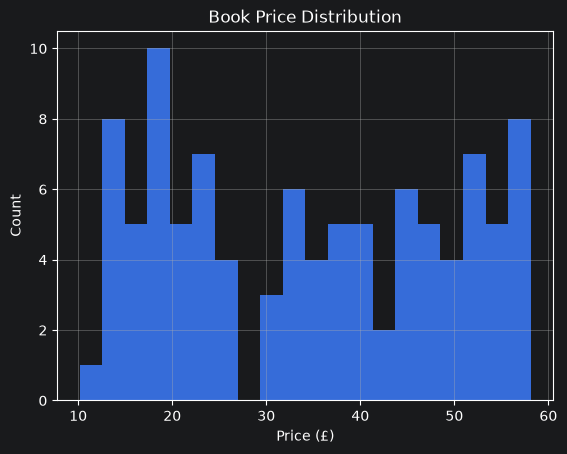

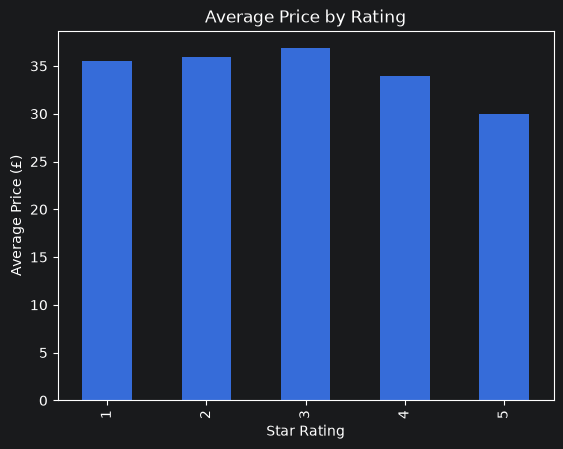

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("books_final_dataset.csv")
import matplotlib.pyplot as plt

# Price distribution
df["price"].hist(bins=20)
plt.title("Book Price Distribution")
plt.xlabel("Price (£)")
plt.ylabel("Count")
plt.show()

# Average price by rating
avg_price = df.groupby("rating")["price"].mean()
avg_price.plot(kind="bar")
plt.title("Average Price by Rating")
plt.xlabel("Star Rating")
plt.ylabel("Average Price (£)")
plt.show()



In [4]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import warnings
warnings.filterwarnings("ignore") # this hides all yellow warnings

# Load data
df = pd.read_csv("books_final_dataset_cleaned.csv")
print(df.head())

X = df[["rating"]]
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Metrics
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"RMSE: {rmse:.2f}")
print(f"R2: {r2:.4f}")


rating_to_predict = pd.DataFrame([[5]], columns=["rating"])
predicted_price = model.predict(rating_to_predict)[0]
print(f"Prediction example: rating=5 -> price £{predicted_price:.2f}")

                                   title  price  rating
0                   A Light in the Attic  51.77       3
1                     Tipping the Velvet  53.74       1
2                             Soumission  50.10       1
3                          Sharp Objects  47.82       4
4  Sapiens: A Brief History of Humankind  54.23       5
RMSE: 12.44
R2: 0.0429
Prediction example: rating=5 -> price £32.89
